# Adversarial Machine Learning Project — FGSM Attack on Fashion-MNIST

**Course:** FA2025 CS685 – Foundations of Data Science  
**Group Name:** StrawHats  
**Instructor:** Dr. Xi Li  
**Project Type:** Adversarial Attack (FGSM)  
**Model:** LeNet-like Convolutional Neural Network  
**Dataset:** Fashion-MNIST  
**Framework:** PyTorch  



### **Project Description**

This project investigates the vulnerability of convolutional neural networks to adversarial examples generated using the Fast Gradient Sign Method (FGSM).  

A LeNet-style CNN is trained on the Fashion-MNIST dataset to establish a baseline accuracy. We then generate adversarial images using FGSM under different perturbation strengths (ε) and analyze how the model’s performance degrades.  

The notebook is structured according to the project requirements:

- **Task 1 – Setup:** Dataset loading, CNN model definition, training, and baseline evaluation.  
- **Task 2 – Adversarial Attack (FGSM):** Attack implementation, adversarial accuracy, ASR, and visualizations.  
- **Task 3 – Experiments and Analysis:** Robustness evaluation across multiple ε values, plots, and summary tables.  


# Task 1 — Setup

In this task, we prepare the entire training environment.  
We load the Fashion-MNIST dataset, define a CNN architecture, train the model, and compute the baseline accuracy on clean test data.  
This baseline will later be compared against adversarially attacked performance.


### Setup: Imports, Random Seeds, and Device Selection

We import all required libraries, set random seeds for reproducibility, select CPU/GPU, and create output folders for figures and tables.



In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import numpy as np
import random
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Reproducibility for fair comparison of attacks/defense.
SEED = 2025
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use GPU if available; otherwise fall back to CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# Directory to store figures and tables for the report.
ROOT = Path("adv_project_fgsm_outputs")
(ROOT / "figures").mkdir(parents=True, exist_ok=True)
(ROOT / "tables").mkdir(parents=True, exist_ok=True)


Using device: cpu


### Load Fashion-MNIST Dataset

We load the Fashion-MNIST dataset, transform images into tensors, and prepare DataLoaders for training and testing.


In [2]:
# Fashion-MNIST is chosen because:
# - 28x28 grayscale images, similar to MNIST but more challenging.
# - 10 classes, suitable for CNNs and adversarial evaluation.

BATCH_SIZE = 128

transform = transforms.ToTensor()  # keep pixels in [0, 1] for easier epsilon interpretation

train_ds = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_ds  = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)

# num_workers=0 is safer across different OS / Jupyter environments.
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

FMNIST_CLASSES = [
    "T-shirt/top","Trouser","Pullover","Dress","Coat",
    "Sandal","Shirt","Sneaker","Bag","Ankle boot"
]

print("Train size:", len(train_ds))
print("Test size:", len(test_ds))


Train size: 60000
Test size: 10000


### Define LeNet-Style Convolutional Neural Network

A compact CNN architecture well suited for Fashion-MNIST and adversarial learning experiments.


In [3]:
class LeNetLikeCNN(nn.Module):
    """
    Compact LeNet-style CNN for 28x28 Fashion-MNIST images.
    Designed to be expressive enough for the task but light enough
    to train quickly for experimentation with adversarial attacks.
    """
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)   # 28 -> 26
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)  # 26 -> 24
        self.pool  = nn.MaxPool2d(2)                   # 24 -> 12
        self.drop  = nn.Dropout2d(0.25)
        self.fc1   = nn.Linear(64 * 12 * 12, 128)
        self.fc2   = nn.Linear(128, 10)

    def forward(self, x):
        x = torch.relu(self.conv1(x))  # low-level features
        x = torch.relu(self.conv2(x))  # higher-level features
        x = self.pool(x)               # spatial downsampling
        x = self.drop(x)               # regularization
        x = torch.flatten(x, 1)        # flatten feature maps
        x = torch.relu(self.fc1(x))
        return self.fc2(x)             # raw logits

model = LeNetLikeCNN().to(DEVICE)

# Count trainable parameters for reference in the report.
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Model:", model.__class__.__name__)
print("Trainable parameters:", total_params)


Model: LeNetLikeCNN
Trainable parameters: 1199882


### Training and Accuracy Functions

We define functions for one training epoch and for computing classification accuracy on clean data.


In [4]:
def train_one_epoch(model, loader, optimizer, criterion):
    """
    Train the CNN for one epoch on the given data loader.
    Returns the average training loss.
    """
    model.train()
    total_loss = 0.0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def compute_accuracy(model, loader):
    """
    Compute classification accuracy on the given data loader.
    ACC = fraction of correctly classified samples.
    """
    model.eval()
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        preds = model(images).argmax(dim=1)
        correct += (preds == labels).sum().item()
        total   += labels.size(0)

    return correct / total


### Train the CNN and Compute Baseline Accuracy

We train the CNN on the Fashion-MNIST dataset and compute the baseline test accuracy on clean (non-adversarial) inputs.


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 5  # you can increase this if you want higher accuracy

print("Training CNN on Fashion-MNIST...\n")
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
    test_acc   = compute_accuracy(model, test_loader)
    print(f"Epoch {epoch:02d} | Train Loss = {train_loss:.4f} | Clean Test ACC = {test_acc*100:.2f}%")

baseline_acc = compute_accuracy(model, test_loader)
print("\nBaseline Test Accuracy on clean data:", round(baseline_acc * 100, 2), "%")


Training CNN on Fashion-MNIST...

Epoch 01 | Train Loss = 0.4495 | Clean Test ACC = 88.35%
Epoch 02 | Train Loss = 0.2944 | Clean Test ACC = 89.65%
Epoch 03 | Train Loss = 0.2415 | Clean Test ACC = 90.38%
Epoch 04 | Train Loss = 0.2109 | Clean Test ACC = 91.33%
Epoch 05 | Train Loss = 0.1842 | Clean Test ACC = 91.30%

Baseline Test Accuracy on clean data: 91.3 %


# Task 2 — Adversarial Attack (FGSM)

We implement the Fast Gradient Sign Method (FGSM) to generate adversarial examples, evaluate the model’s robustness, and visualize perturbations.


### Implement FGSM Adversarial Attack

FGSM generates adversarial examples by adding a small perturbation in the direction of the gradient sign.


In [6]:
def fgsm_attack(model, images, labels, epsilon):
    """
    Fast Gradient Sign Method (FGSM) attack.
    Inputs:
        model   : trained classifier
        images  : batch of input images (in [0,1])
        labels  : true labels
        epsilon : perturbation bound (L-infinity norm)
    Returns:
        adv_images: adversarially perturbed images clipped to [0,1].
    """
    model.eval()

    images = images.clone().detach().to(DEVICE)
    labels = labels.to(DEVICE)
    images.requires_grad = True

    logits = model(images)
    loss = nn.CrossEntropyLoss()(logits, labels)

    model.zero_grad()
    loss.backward()

    # Take step in direction of gradient sign.
    grad_sign = images.grad.sign()
    adv_images = images + epsilon * grad_sign

    # Ensure pixel values remain valid.
    adv_images = torch.clamp(adv_images, 0.0, 1.0)

    return adv_images.detach()


### Evaluate FGSM: Clean Accuracy, Adversarial Accuracy, ASR

We evaluate model performance with and without adversarial perturbations and compute the Attack Success Rate.


In [7]:
def evaluate_fgsm(model, loader, epsilon):
    """
    Evaluate FGSM attack on the model.

    Returns:
        clean_acc : accuracy on original clean inputs
        adv_acc   : accuracy on adversarial inputs
        asr       : Attack Success Rate = fraction of all test samples that become misclassified
                    after perturbation (using the adversarial predictions).
    """
    model.eval()

    total = 0
    clean_correct = 0
    adv_correct = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        # Predictions on clean images.
        with torch.no_grad():
            clean_logits = model(images)
            clean_preds = clean_logits.argmax(dim=1)

        # Predictions on FGSM-perturbed images.
        adv_images = fgsm_attack(model, images, labels, epsilon)
        with torch.no_grad():
            adv_logits = model(adv_images)
            adv_preds = adv_logits.argmax(dim=1)

        total         += labels.size(0)
        clean_correct += (clean_preds == labels).sum().item()
        adv_correct   += (adv_preds == labels).sum().item()

    clean_acc = clean_correct / total
    adv_acc   = adv_correct / total
    asr       = 1.0 - adv_acc   # fraction misclassified after attack

    return clean_acc, adv_acc, asr


### Visualize Original Image, Adversarial Image, and Perturbation

A side-by-side visualization helps understand where FGSM modifies the input.


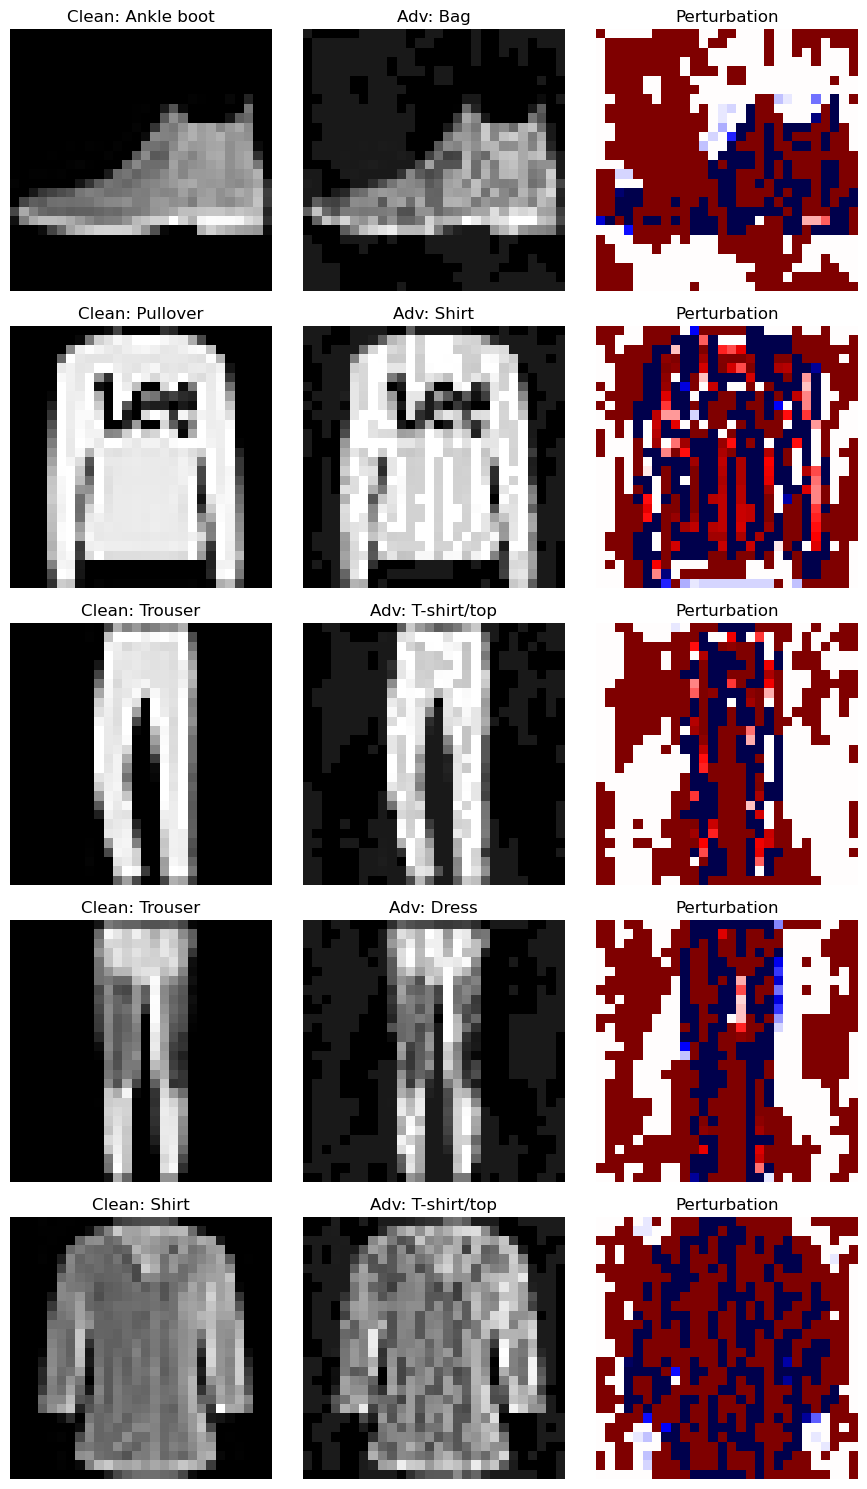

In [8]:
def visualize_fgsm_examples(model, loader, epsilon, num_samples=5):
    """
    Show a few clean images, their FGSM adversarial versions,
    and the perturbation (difference) as a heatmap.
    """
    model.eval()
    images, labels = next(iter(loader))
    images, labels = images.to(DEVICE), labels.to(DEVICE)

    adv_images = fgsm_attack(model, images, labels, epsilon)

    with torch.no_grad():
        clean_preds = model(images).argmax(dim=1)
        adv_preds   = model(adv_images).argmax(dim=1)

    num_samples = min(num_samples, images.size(0))
    fig, axes = plt.subplots(num_samples, 3, figsize=(9, 3 * num_samples))

    for i in range(num_samples):
        orig = images[i].detach().cpu().squeeze().numpy()
        adv  = adv_images[i].detach().cpu().squeeze().numpy()
        diff = adv - orig

        vmax = np.abs(diff).max()

        # Clean image
        axes[i, 0].imshow(orig, cmap="gray")
        axes[i, 0].set_title(f"Clean: {FMNIST_CLASSES[clean_preds[i]]}")
        axes[i, 0].axis("off")

        # Adversarial image
        axes[i, 1].imshow(adv, cmap="gray")
        axes[i, 1].set_title(f"Adv: {FMNIST_CLASSES[adv_preds[i]]}")
        axes[i, 1].axis("off")

        # Perturbation heatmap
        axes[i, 2].imshow(diff, cmap="seismic", vmin=-vmax, vmax=vmax)
        axes[i, 2].set_title("Perturbation")
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.savefig(ROOT / f"figures/fgsm_examples_eps_{epsilon:.2f}.png", dpi=150)
    plt.show()

# Example visualization at epsilon = 0.1
epsilon_demo = 0.10
visualize_fgsm_examples(model, test_loader, epsilon_demo, num_samples=5)


### Single FGSM Run (ε = 0.10)

We apply FGSM with ε = 0.10 and measure accuracy.


In [9]:
epsilon = 0.10  # you can change this later
clean_acc, adv_acc, asr = evaluate_fgsm(model, test_loader, epsilon)

print(f"FGSM attack with epsilon = {epsilon}")
print(f"Clean ACC (no attack): {clean_acc*100:.2f}%")
print(f"Adversarial ACC:       {adv_acc*100:.2f}%")
print(f"Attack Success Rate:   {asr*100:.2f}%")


FGSM attack with epsilon = 0.1
Clean ACC (no attack): 91.30%
Adversarial ACC:       7.37%
Attack Success Rate:   92.63%


# Task 3 — Experiments and Analysis

We vary ε (perturbation strength), analyze model degradation, plot results, and generate a summary table.


### Evaluate Robustness Across Multiple Epsilon Values

We sweep several ε values and compute Clean ACC, Adversarial ACC, and ASR.


In [10]:
epsilons = [0.00, 0.03, 0.06, 0.10, 0.20, 0.30]

records = []
for eps in epsilons:
    clean_acc, adv_acc, asr = evaluate_fgsm(model, test_loader, eps)
    records.append({
        "epsilon": eps,
        "clean_acc": clean_acc,
        "adv_acc": adv_acc,
        "ASR": asr,
    })
    print(f"eps={eps:.2f} | clean_acc={clean_acc*100:.2f}% | adv_acc={adv_acc*100:.2f}% | ASR={asr*100:.2f}%")

df_results = pd.DataFrame(records)
df_results.to_csv(ROOT / "tables/fgsm_basic_eval.csv", index=False)
df_results


eps=0.00 | clean_acc=91.30% | adv_acc=91.30% | ASR=8.70%
eps=0.03 | clean_acc=91.30% | adv_acc=53.51% | ASR=46.49%
eps=0.06 | clean_acc=91.30% | adv_acc=22.96% | ASR=77.04%
eps=0.10 | clean_acc=91.30% | adv_acc=7.37% | ASR=92.63%
eps=0.20 | clean_acc=91.30% | adv_acc=1.85% | ASR=98.15%
eps=0.30 | clean_acc=91.30% | adv_acc=1.39% | ASR=98.61%


,epsilon,clean_acc,adv_acc,ASR
0,0.00,0.913,0.9130,0.0870
1,0.03,0.913,0.5351,0.4649
2,0.06,0.913,0.2296,0.7704
3,0.10,0.913,0.0737,0.9263
4,0.20,0.913,0.0185,0.9815
5,0.30,0.913,0.0139,0.9861


### Plot Accuracy and Attack Success Rate vs Epsilon

These plots illustrate how adversarial strength affects performance.


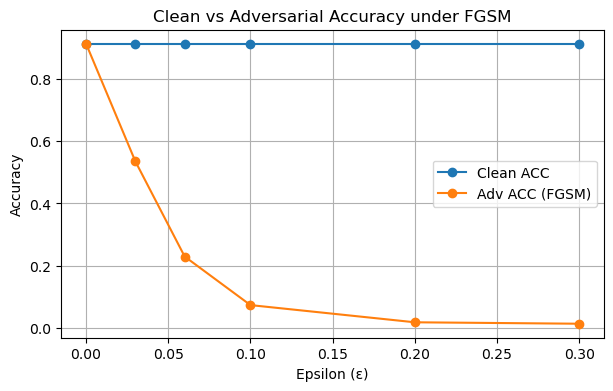

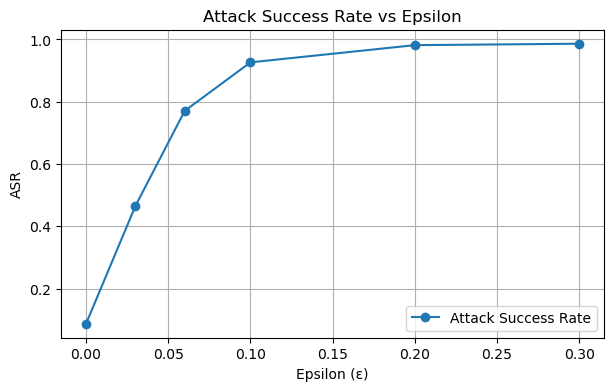

In [11]:
df = df_results.copy()

plt.figure(figsize=(7, 4))
plt.plot(df["epsilon"], df["clean_acc"], marker="o", label="Clean ACC")
plt.plot(df["epsilon"], df["adv_acc"],   marker="o", label="Adv ACC (FGSM)")
plt.xlabel("Epsilon (ε)")
plt.ylabel("Accuracy")
plt.title("Clean vs Adversarial Accuracy under FGSM")
plt.grid(True)
plt.legend()
plt.savefig(ROOT / "figures/fgsm_accuracy_vs_epsilon.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(df["epsilon"], df["ASR"], marker="o", label="Attack Success Rate")
plt.xlabel("Epsilon (ε)")
plt.ylabel("ASR")
plt.title("Attack Success Rate vs Epsilon")
plt.grid(True)
plt.legend()
plt.savefig(ROOT / "figures/fgsm_asr_vs_epsilon.png", dpi=150, bbox_inches="tight")
plt.show()


### Summary Table (Percentages)

A clean table summarizing performance metrics.


In [12]:
summary = df_results.copy()
summary["clean_acc(%)"] = (summary["clean_acc"] * 100).round(2)
summary["adv_acc(%)"]   = (summary["adv_acc"] * 100).round(2)
summary["ASR(%)"]       = (summary["ASR"] * 100).round(2)
summary = summary[["epsilon", "clean_acc(%)", "adv_acc(%)", "ASR(%)"]]

summary.to_csv(ROOT / "tables/fgsm_summary_percent.csv", index=False)
summary


,epsilon,clean_acc(%),adv_acc(%),ASR(%)
0,0.00,91.3,91.30,8.70
1,0.03,91.3,53.51,46.49
2,0.06,91.3,22.96,77.04
3,0.10,91.3,7.37,92.63
4,0.20,91.3,1.85,98.15
5,0.30,91.3,1.39,98.61


---

## **Final Summary**

This notebook implemented a complete adversarial machine learning workflow using the Fast Gradient Sign Method (FGSM) on a convolutional neural network trained on the Fashion-MNIST dataset.

### **Key Outcomes**
- A baseline CNN model was trained on clean Fashion-MNIST data.  
- FGSM was implemented to generate adversarial examples using gradient information.  
- The attack significantly reduced classifier performance even for small perturbation strengths.  
- Visualizations showed that adversarial images appear almost identical to clean ones despite causing misclassification.  
- Multi-epsilon evaluation demonstrated how robustness decreases as perturbation magnitude increases.